# PD Calibration Under Validation: Long-Run Average Default Rates, Through-the-Cycle versus Point-in-Time Rating Systems, Binomial, Jeffreys and Traffic-Light Tests, Grade Monotonicity and a Margin of Conservatism on Twenty Years of U.S. Mortgages

A rating system ranks borrowers; calibration attaches a probability of default to each grade. Under the internal-ratings-based approach the PD of a grade must be its **long-run average** one-year default rate, estimated over a period that contains good and bad years, plus a **margin of conservatism** for what the data cannot tell. Validators then test, year after year, whether the observed default rates are consistent with those PDs. The tests are simple, but how to read them is not: a through-the-cycle PD *should* be exceeded in a recession, and a binomial test that ignores default correlation will flag it. This notebook builds two rating systems for U.S. mortgages, one through-the-cycle-leaning and one point-in-time, calibrates both to long-run averages from twenty years of loan-level data, and runs the standard validation battery on loans the models never saw and on a newer book from a different lender.

**What it does.**

1. It reads loan-level origination and monthly performance data for Fannie Mae loans originated in 2005–2008 (followed to 2025) and Freddie Mac loans originated in 2018–2023, and turns them into annual snapshots: each performing loan at each year-end, with a flag for default (90 days past due or a credit event) in the next twelve months.
2. It builds a through-the-cycle-leaning scorecard (logistic regression on borrower and loan attributes, without house prices or unemployment) and a point-in-time model (LightGBM with monotone constraints that also sees mark-to-market loan-to-value and state unemployment), both trained on 2005–2012.
3. It maps both onto an eleven-grade master scale and calibrates each grade to the long-run average of its annual default rates. It checks whether the observation period is representative of the long run with a 35-year bank delinquency series.
4. It runs the validation tests by grade and year: one-sided binomial, Jeffreys, the traffic-light approach with independent and correlated defaults, Hosmer–Lemeshow, grade monotonicity, discrimination, rating migration and the degree of point-in-time-ness.
5. It quantifies a margin of conservatism in three categories (data deficiencies, representativeness, statistical uncertainty) and tests the final PDs on the newer book.

**Data.** Fannie Mae Single-Family Loan Performance Data and Freddie Mac Single-Family Loan-Level Dataset (samples, downloaded once by hand into `data/` at the repository root); state house price indices, state unemployment rates, the 30-year mortgage rate and the delinquency rate on bank single-family mortgages (FRED).

**Methods.** Annual cohort default rates, logistic regression, LightGBM with monotone constraints, a master scale, long-run average calibration, block bootstrap, binomial and Jeffreys tests, the traffic-light approach with a Vasicek one-factor adjustment, Hosmer–Lemeshow, adjacent-grade tests of monotonicity, AUC, migration matrices and an EBA-style margin of conservatism.

**Key output.** Long-run average PDs by grade with their margin of conservatism; year-by-year test results for both rating systems on held-out loans and on the newer book; how many grade-years fail with and without default correlation; and how point-in-time each system is.

## 1. Calibration and its validation

**Long-run average.** Basel requires the PD of a grade to be "a long-run average of one-year default rates" (BCBS, 2006, ¶447). The European Banking Authority's guidelines on PD estimation make it concrete: the long-run average is the arithmetic mean of one-year default rates over a historical observation period that must contain a representative mix of good and bad years, and if the available data do not, the estimate must be adjusted (EBA, 2017).

**Through-the-cycle and point-in-time.** A rating system is *point-in-time* (PIT) if borrowers move between grades as the economy changes, so that each grade's default rate stays roughly constant; it is *through-the-cycle* (TTC) if borrowers keep their grades and each grade's default rate rises in recessions. Most systems are hybrids. The calibration to long-run averages makes the PD of each grade TTC either way; what differs is how capital moves over the cycle and how the tests behave.

**Validation tests.** For a grade with N borrowers, D defaults and PD *p*:
- **Binomial test:** under independence, D ~ Binomial(N, *p*); the one-sided p-value P(X ≥ D) flags underestimation.
- **Jeffreys test:** the posterior of the default rate under a Jeffreys prior is Beta(D + ½, N − D + ½); the p-value is the posterior probability that the true rate is below *p*. The European Central Bank uses it in its instructions for reporting validation results (ECB, 2019).
- **Traffic lights:** green if the p-value is above 5%, yellow between 5% and 0.1%, red below 0.1% (Tasche, 2003). With correlated defaults the count of defaults is far more dispersed than a binomial; under the Vasicek one-factor model with asset correlation R the test uses a mixture of binomials, and a TTC PD exceeded in a recession is no longer an outlier.
- **Hosmer–Lemeshow:** a χ² test across all grades of a year.
- **Monotonicity:** observed default rates must rise from the best grade to the worst.

**Margin of conservatism.** EBA (2017) requires a margin for (A) identified data and methodological deficiencies, (B) relevant changes in underwriting, portfolio or economic conditions that make the data less representative, and (C) the general estimation error. The final PD is the best estimate plus the margin, and never below the regulatory floor (0.05% for residential mortgages under the finalised Basel III framework).

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import zipfile
from concurrent.futures import ThreadPoolExecutor

import lightgbm as lgb
from matplotlib.colors import ListedColormap
from scipy.stats import beta, binom, chi2, norm
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 2005
rng = np.random.default_rng(SEED)
# snapshots used to train the two rating models
DEV_YEARS = range(2005, 2013)
# share of Fannie Mae loans never used for training or calibration
HOLDOUT = 0.30
# master-scale PD bounds
MASTER = [
    0,
    0.0005,
    0.001,
    0.002,
    0.004,
    0.008,
    0.016,
    0.032,
    0.064,
    0.128,
    0.256,
    1.0,
]
GRADES = list(range(1, len(MASTER)))
BASEL_R, PD_FLOOR, CONF, MIN_OBS = 0.15, 0.0005, 0.90, 30
VINTAGES = {
    "Fannie Mae": ("fannie_mae", [2005, 2006, 2007, 2008]),
    "Freddie Mac": ("freddie_mac", [2018, 2019, 2020, 2021, 2022, 2023]),
}
STATES = [
    "AK",
    "AL",
    "AR",
    "AZ",
    "CA",
    "CO",
    "CT",
    "DC",
    "DE",
    "FL",
    "GA",
    "HI",
    "IA",
    "ID",
    "IL",
    "IN",
    "KS",
    "KY",
    "LA",
    "MA",
    "MD",
    "ME",
    "MI",
    "MN",
    "MO",
    "MS",
    "MT",
    "NC",
    "ND",
    "NE",
    "NH",
    "NJ",
    "NM",
    "NV",
    "NY",
    "OH",
    "OK",
    "OR",
    "PA",
    "RI",
    "SC",
    "SD",
    "TN",
    "TX",
    "UT",
    "VA",
    "VT",
    "WA",
    "WI",
    "WV",
    "WY",
]

print(f"lightgbm {lgb.__version__} · run on {dt.date.today():%Y-%m-%d}")

lightgbm 4.7.0 · run on 2026-11-04


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 3. Annual snapshots of two mortgage books

Both datasets share one layout: an origination file (credit score, loan-to-value, debt-to-income, note rate, purpose, occupancy and so on) and a monthly performance file. The Fannie Mae files for 2005–2008 are samples of 50,000 loans per year in the Freddie Mac sample format, followed until the end of 2025. Both are licensed for research and stay in `data/`, never in the repository.

**Observation.** Every loan that is performing (less than 90 days past due and never in default before) at the end of December of year *t* is one observation of year *t*.

**Default.** The loan reaches 90 days past due, or ends with a short sale, third-party sale, note sale or REO, within the next twelve months. This is the Basel 90-days-past-due definition, with one adjustment: arrears accumulated while the loan was in a COVID-19 forbearance plan do not count, because the borrower had permission not to pay. That follows the EBA's guidelines on payment moratoria (EBA, 2020), which told banks not to treat such loans as defaulted automatically. A loan that reaches 90 days past due after its forbearance ends does count. Section 8 shows what the 2020 default rates would have been without the adjustment.

**Two books.** The Fannie Mae loans form a *closed book*: no new loans enter after 2008, so the book ages, shrinks and is left with the loans that survived the crisis. The Freddie Mac loans of 2018–2023 are a newer book, written under post-crisis underwriting rules, and serve as an out-of-time and out-of-portfolio test.

In [3]:
OC = [
    "fico",
    "first_pay",
    "fthb",
    "maturity",
    "msa",
    "mi_pct",
    "units",
    "occupancy",
    "cltv",
    "dti",
    "upb",
    "ltv",
    "rate",
    "channel",
    "ppm",
    "amort",
    "state",
    "prop_type",
    "zip",
    "loan_id",
    "purpose",
    "term",
    "n_borrowers",
]
DEFAULT_ZB = {"02", "03", "09", "15"}
KEEP = [
    "loan_id",
    "year",
    "default",
    "default_incl_forbearance",
    "upb_now",
    "age",
    "dlq",
    "fico",
    "cltv",
    "dti",
    "rate",
    "upb",
    "state",
    "purpose",
    "occupancy",
    "fthb",
    "units",
    "n_borrowers",
    "prop_type",
    "orig_month",
    "amort",
    "term",
]


def find_shared(name):
    for d in [PROJECT_DIR, *PROJECT_DIR.parents]:
        if (d / "data" / name).exists():
            return d / "data" / name
    return None


def read_book(zp, year):
    with zipfile.ZipFile(zp) as z:
        o = pd.read_csv(
            z.open(f"sample_orig_{year}.txt"),
            sep="|",
            header=None,
            usecols=range(len(OC)),
            names=OC,
            dtype=str,
        )
        snaps, bads = [], []
        for ch in pd.read_csv(
            z.open(f"sample_perf_{year}.txt"),
            sep="|",
            header=None,
            usecols=[0, 1, 2, 3, 4, 8, 29],
            names=[
                "loan_id",
                "period",
                "upb_now",
                "dlq",
                "age",
                "zb",
                "assist",
            ],
            dtype=str,
            chunksize=3_000_000,
        ):
            dlq = pd.to_numeric(
                ch["dlq"].replace({"RA": "99"}), errors="coerce"
            )
            bad = (dlq >= 3) | ch["zb"].isin(DEFAULT_ZB)
            bads.append(ch.loc[bad, ["loan_id", "period", "assist"]])
            dec = ch["period"].str.endswith("12") & ch["zb"].isna()
            s = ch.loc[dec, ["loan_id", "period", "upb_now", "age"]].copy()
            s["dlq"] = dlq[dec]
            snaps.append(s)
            last = ch["period"].max()
    b = pd.concat(bads)
    first_any = b.groupby("loan_id")["period"].min().rename("first_any")
    first_nf = (
        b[b["assist"].ne("F")]
        .groupby("loan_id")["period"]
        .min()
        .rename("first_default")
    )
    s = (
        pd.concat(snaps)
        .join(first_any, on="loan_id")
        .join(first_nf, on="loan_id")
    )
    per = s["period"].astype(int)
    fd = pd.to_numeric(s["first_default"], errors="coerce")
    fa = pd.to_numeric(s["first_any"], errors="coerce")
    # performing, full 12-month window
    s = s[(s["dlq"] < 3) & ~(fd <= per) & (per + 100 <= int(last))].copy()
    per, fd, fa = per[s.index], fd[s.index], fa[s.index]
    s["default"] = ((fd > per) & (fd <= per + 100)).astype("int8")
    s["default_incl_forbearance"] = (
        ((fa > per) & (fa <= per + 100)) | (s["default"] == 1)
    ).astype("int8")
    s["year"] = per // 100
    s["upb_now"] = pd.to_numeric(s["upb_now"], errors="coerce")
    s["age"] = pd.to_numeric(s["age"], errors="coerce")
    o["orig_month"] = (
        pd.to_datetime(o["first_pay"], format="%Y%m") - pd.DateOffset(months=2)
    ).dt.strftime("%Y-%m")
    s = s.merge(
        o.drop(columns=["upb"]).join(pd.to_numeric(o["upb"], errors="coerce")),
        on="loan_id",
    )
    return s[KEEP]


def load_all():
    out = []
    for src, (folder, years) in VINTAGES.items():
        base = find_shared(folder)
        if base is None:
            continue
        for y in years:
            hits = [
                h
                for h in base.rglob(f"sample_{y}.zip")
                if "_to_delete" not in h.parts
            ]
            if hits:
                v = read_book(min(hits, key=lambda h: len(h.parts)), y)
                v["book"], v["vintage"] = src, y
                out.append(v)
    return pd.concat(out, ignore_index=True)


SNAP = cached("mortgage_annual_snapshots_v2", load_all, max_age_hours=24 * 60)
for c in [
    "fico",
    "cltv",
    "dti",
    "rate",
    "upb",
    "units",
    "n_borrowers",
    "term",
]:
    SNAP[c] = pd.to_numeric(SNAP[c], errors="coerce")
SNAP = SNAP[
    (SNAP["amort"] == "FRM")
    & SNAP["term"].between(300, 360)
    & SNAP["fico"].between(300, 850)
    & SNAP["cltv"].between(1, 200)
    & SNAP["rate"].between(1, 15)
    & SNAP["state"].isin(STATES)
].copy()
SNAP["dti_missing"] = (~SNAP["dti"].between(1, 65)).astype("int8")
SNAP["dti"] = SNAP["dti"].where(SNAP["dti"].between(1, 65))
# early months report a zero balance
SNAP["upb_now"] = SNAP["upb_now"].where(SNAP["upb_now"] > 0, SNAP["upb"])
BOOKS = SNAP.groupby(["book", "year"]).agg(
    loans=("default", "size"),
    defaults=("default", "sum"),
    default_rate=("default", "mean"),
    default_rate_incl_forbearance=("default_incl_forbearance", "mean"),
)
print(f"{len(SNAP):,} loan-years from {SNAP['loan_id'].nunique():,} loans")
BOOKS.unstack(0).style.format({
    c: "{:.2%}" if c[0].startswith("default_rate") else "{:,.0f}"
    for c in BOOKS.unstack(0).columns
})

1,453,047 loan-years from 396,514 loans


## 4. Macro data and features

The point-in-time model needs the loan's current position, not just its position at origination:
- **Mark-to-market loan-to-value:** the combined LTV at origination, times the share of the balance still outstanding, times the change in the state house price index since origination.
- **House prices and unemployment:** the twelve-month change in the state house price index, and the level and twelve-month change of the state unemployment rate.
- **Spread at origination:** the note rate minus the 30-year mortgage rate in the month of origination. It measures risk the lender priced in, and unlike the rate itself it is comparable between 2005 and 2020.

Both models also see the loan's age and whether it is current, 30 or 60 days past due at the snapshot, the standard behavioural variables of a retail PD model.

In [4]:
def fetch_macro():
    ids = {f"hpi_{s}": f"{s}STHPI" for s in STATES} | {
        f"ur_{s}": f"{s}UR" for s in STATES
    }
    ids |= {"pmms": "MORTGAGE30US", "dlq_banks": "DRSFRMACBS"}
    with ThreadPoolExecutor(6) as ex:
        got = dict(
            zip(ids, ex.map(lambda i: fred.get_series(i), ids.values()))
        )
    return pd.DataFrame({k: v.resample("MS").mean() for k, v in got.items()})


MACRO = cached(
    "fred_state_hpi_unemployment", fetch_macro, max_age_hours=24 * 30
)
MACRO.index = pd.to_datetime(MACRO.index)
M = MACRO.resample("MS").mean().ffill()
HPI = M[[f"hpi_{s}" for s in STATES]].set_axis(STATES, axis=1)
UR = M[[f"ur_{s}" for s in STATES]].set_axis(STATES, axis=1)


def lookup(frame, months, states):
    rows = frame.index.get_indexer(pd.to_datetime(months))
    cols = frame.columns.get_indexer(states)
    out = np.full(len(rows), np.nan)
    ok = (rows >= 0) & (cols >= 0)
    out[ok] = frame.to_numpy()[rows[ok], cols[ok]]
    return out


snap_m = SNAP["year"].astype(str) + "-12"
prev_m = (SNAP["year"] - 1).astype(str) + "-12"
SNAP["mtm_ltv"] = (
    SNAP["cltv"]
    * (SNAP["upb_now"] / SNAP["upb"]).clip(0, 1.2)
    * lookup(HPI, SNAP["orig_month"], SNAP["state"])
    / lookup(HPI, snap_m, SNAP["state"])
)
SNAP["hpi_chg"] = (
    lookup(HPI, snap_m, SNAP["state"]) / lookup(HPI, prev_m, SNAP["state"]) - 1
)
SNAP["ur"] = lookup(UR, snap_m, SNAP["state"])
SNAP["ur_chg"] = SNAP["ur"] - lookup(UR, prev_m, SNAP["state"])
SNAP["sato"] = (
    SNAP["rate"]
    - M["pmms"].reindex(pd.to_datetime(SNAP["orig_month"])).to_numpy()
)
for c, m in [
    ("purpose", {"P": 0, "C": 1, "N": 2}),
    ("occupancy", {"P": 0, "S": 1, "I": 2}),
    ("fthb", {"Y": 1, "N": 0}),
    ("prop_type", {"SF": 0, "PU": 1, "CO": 2, "MH": 3, "CP": 4}),
]:
    SNAP[c + "_c"] = SNAP[c].map(m).fillna(-1).astype(int)
SNAP["multi_borrower"] = (SNAP["n_borrowers"] >= 2).astype(int)
SNAP["multi_unit"] = (SNAP["units"] >= 2).astype(int)
SNAP = SNAP.dropna(subset=["mtm_ltv", "ur", "sato"]).reset_index(drop=True)

ids = SNAP.loc[SNAP["book"] == "Fannie Mae", "loan_id"].unique()
hold_ids = set(rng.choice(ids, int(len(ids) * HOLDOUT), replace=False))
SNAP["sample"] = np.where(
    SNAP["book"] == "Freddie Mac",
    "new book",
    np.where(SNAP["loan_id"].isin(hold_ids), "holdout", "calibration"),
)
SNAP.groupby(["book", "sample"]).agg(
    loan_years=("default", "size"),
    loans=("loan_id", "nunique"),
    default_rate=("default", "mean"),
    mean_fico=("fico", "mean"),
    mean_cltv=("cltv", "mean"),
    mean_mtm_ltv=("mtm_ltv", "mean"),
).style.format({
    "loan_years": "{:,.0f}",
    "loans": "{:,.0f}",
    "default_rate": "{:.2%}",
    "mean_fico": "{:.0f}",
    "mean_cltv": "{:.1f}",
    "mean_mtm_ltv": "{:.1f}",
})

## 5. Two rating systems

Both models are trained on the calibration loans of the Fannie Mae book, snapshots 2005–2012, which span the run-up, the crisis and the early recovery.

- **Through-the-cycle-leaning scorecard.** A logistic regression on binned credit score, combined LTV at origination, debt-to-income, spread at origination and loan age, plus the delinquency status and the categorical loan attributes. It sees nothing about house prices or unemployment, so a borrower's grade changes only with seasoning and payment behaviour.
- **Point-in-time model.** LightGBM on the same attributes plus mark-to-market LTV, the change in house prices and the state unemployment rate and its change, with monotone constraints where the sign is known (higher score, lower PD; higher LTV, unemployment or delinquency, higher PD).

Each model's raw PD is mapped to an eleven-grade **master scale** with bounds that double from 0.05% to 25.6%. The grades, not the raw PDs, are then calibrated.

In [5]:
CAT = [
    "purpose_c",
    "occupancy_c",
    "fthb_c",
    "prop_type_c",
    "multi_borrower",
    "multi_unit",
    "dlq",
]
BINS = {
    "fico": [300, 620, 660, 700, 740, 780, 851],
    "cltv": [0, 60, 70, 80, 90, 95, 201],
    "dti": [0, 25, 35, 43, 50, 66],
    "sato": [-9, -0.25, 0, 0.25, 0.5, 1, 9],
    "age": [-1, 12, 24, 48, 84, 600],
}


def scorecard_x(d):
    parts = [
        pd.get_dummies(pd.cut(d[c], b), prefix=c, dtype=float)
        for c, b in BINS.items()
    ]
    parts += [
        pd.get_dummies(d[c].astype(str), prefix=c, dtype=float) for c in CAT
    ] + [d[["dti_missing"]].astype(float)]
    return pd.concat(parts, axis=1)


PIT_F = [
    "fico",
    "cltv",
    "dti",
    "sato",
    "age",
    "dlq",
    "mtm_ltv",
    "hpi_chg",
    "ur",
    "ur_chg",
] + CAT[:-1]
MONO = {
    "fico": -1,
    "cltv": 1,
    "dti": 1,
    "dlq": 1,
    "mtm_ltv": 1,
    "hpi_chg": -1,
    "ur": 1,
    "ur_chg": 1,
}

dev = SNAP[(SNAP["sample"] == "calibration") & SNAP["year"].isin(DEV_YEARS)]
XS = scorecard_x(SNAP)
logit = LogisticRegression(C=0.5, max_iter=3000).fit(
    XS.loc[dev.index], dev["default"]
)
gbm = lgb.LGBMClassifier(
    n_estimators=500,
    learning_rate=0.03,
    num_leaves=31,
    min_child_samples=300,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    reg_lambda=5,
    random_state=SEED,
    verbose=-1,
    monotone_constraints=[MONO.get(f, 0) for f in PIT_F],
)
gbm.fit(dev[PIT_F], dev["default"])
SNAP["pd_ttc_raw"] = logit.predict_proba(XS)[:, 1]
SNAP["pd_pit_raw"] = gbm.predict_proba(SNAP[PIT_F])[:, 1]
SYSTEMS = {"TTC-leaning scorecard": "ttc", "PIT model": "pit"}
for s in SYSTEMS.values():
    SNAP[f"grade_{s}"] = np.digitize(SNAP[f"pd_{s}_raw"], MASTER[1:-1]) + 1

AUC = SNAP.groupby(["sample", "year"]).apply(
    lambda g: pd.Series({
        name: (
            roc_auc_score(g["default"], g[f"pd_{s}_raw"])
            if 0 < g["default"].sum() < len(g)
            else np.nan
        )
        for name, s in SYSTEMS.items()
    })
)
AUC_POOLED = SNAP.groupby("sample").apply(
    lambda g: pd.Series({
        name: roc_auc_score(g["default"], g[f"pd_{s}_raw"])
        for name, s in SYSTEMS.items()
    })
)
display(AUC_POOLED.style.format("{:.3f}").set_caption("AUC, all years pooled"))
AUC.unstack(0).style.format("{:.3f}").set_caption("AUC by snapshot year")

,TTC-leaning scorecard,PIT model
sample,,
calibration,0.820,0.873
holdout,0.818,0.864
new book,0.819,0.842


## 6. Long-run average PDs and whether the period is representative

**Portfolio and grade LRAs.** For each grade, the long-run average is the arithmetic mean of its annual default rates on the calibration loans, using every year in which the grade has at least 30 loans. A grade's LRA must not fall as the grade worsens; where it does, adjacent grades are pooled (isotonic regression).

**Representativeness.** The observation years 2005–2024 contain the worst mortgage crisis since the 1930s, but they are only twenty years. The bank single-family delinquency rate, published since 1991, is a proxy for the cycle: if its average over the observation years is below its average since 1991, the observation period is benign relative to the long run and the LRA should be scaled up; if it is above, no downward adjustment is made.

**The window matters.** The table also shows the LRA that a bank would have computed with shorter windows: only the boom years before the crisis, or only the benign decade after it.

In [6]:
def isotonic(x, w):
    """Pool-adjacent-violators for an increasing sequence."""
    blocks = [[v, wt, 1] for v, wt in zip(x, w)]
    i = 0
    while i < len(blocks) - 1:
        if blocks[i][0] > blocks[i + 1][0]:
            v = (
                blocks[i][0] * blocks[i][1]
                + blocks[i + 1][0] * blocks[i + 1][1]
            ) / (blocks[i][1] + blocks[i + 1][1])
            blocks[i] = [
                v,
                blocks[i][1] + blocks[i + 1][1],
                blocks[i][2] + blocks[i + 1][2],
            ]
            del blocks[i + 1]
            i = max(i - 1, 0)
        else:
            i += 1
    return np.concatenate([[b[0]] * b[2] for b in blocks])


def grade_lra(d, gcol, years=None):
    if years is not None:
        d = d[d["year"].isin(years)]
    yr = d.groupby([gcol, "year"])["default"].agg(["mean", "size"])
    yr = yr[yr["size"] >= MIN_OBS]
    lra = yr["mean"].groupby(level=0).mean().reindex(GRADES)
    n = d.groupby(gcol).size().reindex(GRADES).fillna(0)
    lra = lra.interpolate(limit_direction="both")
    return (
        pd.Series(isotonic(lra.to_numpy(), n.to_numpy() + 1), index=GRADES),
        lra,
        yr,
    )


CAL = SNAP[SNAP["sample"] == "calibration"]
ANNUAL = CAL.groupby("year")["default"].mean()
LRA_PORTFOLIO = ANNUAL.mean()
LRA, LRA_RAW, YR = {}, {}, {}
for s in SYSTEMS.values():
    LRA[s], LRA_RAW[s], YR[s] = grade_lra(CAL, f"grade_{s}")

proxy = MACRO["dlq_banks"].dropna() / 100
obs_years = sorted(CAL["year"].unique())
# outcome years
proxy_obs = proxy[proxy.index.year.isin([y + 1 for y in obs_years])].mean()
REPRESENT = pd.Series({
    "bank delinquency rate, 1991–2025 average": proxy.mean(),
    f"bank delinquency rate, outcome years {obs_years[0] + 1}–{obs_years[-1] + 1}": (
        proxy_obs
    ),
    "ratio long run / observation period": proxy.mean() / proxy_obs,
})
WINDOWS = {
    "full period 2005–2024": obs_years,
    "pre-crisis 2005–2006": [2005, 2006],
    "crisis 2007–2010": list(range(2007, 2011)),
    "post-crisis 2013–2019": list(range(2013, 2020)),
}
WIN = pd.DataFrame({
    w: {
        "portfolio LRA": ANNUAL.reindex(y).mean(),
        **{
            f"grade {g} LRA, TTC-leaning": grade_lra(CAL, "grade_ttc", y)[0][g]
            for g in [3, 5, 7]
        },
    }
    for w, y in WINDOWS.items()
}).T
display(REPRESENT.to_frame("value").style.format("{:.3f}"))
display(
    WIN.style.format("{:.2%}").set_caption(
        "Long-run average default rate by observation window (calibration"
        " loans)"
    )
)
GR = pd.DataFrame(
    {f"{n}: LRA": LRA[s] for n, s in SYSTEMS.items()}
    | {
        f"{n}: share of loan-years": (
            CAL[f"grade_{s}"]
            .value_counts(normalize=True)
            .reindex(GRADES)
            .fillna(0)
        )
        for n, s in SYSTEMS.items()
    }
)
GR.index = [f"{g} ({MASTER[g - 1]:.2%}–{MASTER[g]:.2%})" for g in GRADES]
print(
    f"Portfolio long-run average default rate (mean of {len(ANNUAL)} annual"
    f" rates): {LRA_PORTFOLIO:.2%}"
)
GR.style.format("{:.2%}")

,value
"bank delinquency rate, 1991–2025 average",0.037
"bank delinquency rate, outcome years 2006–2025",0.049
ratio long run / observation period,0.760


,portfolio LRA,"grade 3 LRA, TTC-leaning","grade 5 LRA, TTC-leaning","grade 7 LRA, TTC-leaning"
full period 2005–2024,2.19%,0.11%,0.52%,1.47%
pre-crisis 2005–2006,0.78%,0.00%,0.03%,0.71%
crisis 2007–2010,4.24%,0.00%,0.43%,2.91%
post-crisis 2013–2019,1.95%,0.19%,0.64%,1.29%


Portfolio long-run average default rate (mean of 20 annual rates): 2.19%


,TTC-leaning scorecard: LRA,PIT model: LRA,TTC-leaning scorecard: share of loan-years,PIT model: share of loan-years
1 (0.00%–0.05%),0.11%,0.11%,0.00%,3.64%
2 (0.05%–0.10%),0.11%,0.21%,0.00%,4.93%
3 (0.10%–0.20%),0.11%,0.44%,0.50%,8.02%
4 (0.20%–0.40%),0.20%,0.44%,3.97%,11.41%
5 (0.40%–0.80%),0.52%,0.80%,13.44%,15.06%
6 (0.80%–1.60%),0.80%,1.21%,25.78%,18.52%
7 (1.60%–3.20%),1.47%,2.05%,31.61%,17.96%
8 (3.20%–6.40%),2.35%,5.92%,18.91%,11.44%
9 (6.40%–12.80%),5.90%,11.32%,2.77%,4.82%
10 (12.80%–25.60%),18.12%,17.04%,0.63%,2.01%


## 7. Margin of conservatism

Following the EBA's three categories:

- **A. Data deficiencies.** About 3% of the Fannie Mae loan-years have no usable debt-to-income ratio. The margin is the increase in the portfolio LRA if those loans are assumed to default like the worst decile of debt-to-income, relative to the LRA with the loans as they are.
- **B. Representativeness.** The ratio of the long-run bank delinquency rate to its average over the observation period, minus one, when positive.
- **C. General estimation error.** The annual default rates are few and serially correlated. A block bootstrap (blocks of three years, 5,000 draws) gives the distribution of their mean; the margin is the distance from the LRA to the 90th percentile, relative to the LRA.

The margins are added and applied to the grade LRAs: PD = max(LRA × (1 + A + B + C), 0.05%).

In [7]:
def block_boot_mean(y, n=5000, block=3):
    y = np.asarray(y)
    k = int(np.ceil(len(y) / block))
    starts = rng.integers(0, len(y) - block + 1, size=(n, k))
    idx = (starts[:, :, None] + np.arange(block)).reshape(n, -1)[:, : len(y)]
    return y[idx].mean(axis=1)


worst_dti = (
    CAL.loc[CAL["dti"] >= CAL["dti"].quantile(0.9)]
    .groupby("year")["default"]
    .mean()
)
adj = (
    CAL["default"]
    .astype(float)
    .where(
        CAL["dti_missing"] == 0,
        CAL["year"].map(worst_dti).fillna(CAL["default"].mean()),
    )
)
moc_a = max(adj.groupby(CAL["year"]).mean().mean() / LRA_PORTFOLIO - 1, 0)
moc_b = max(REPRESENT.iloc[2] - 1, 0)
boot = block_boot_mean(ANNUAL.to_numpy())
moc_c = max(np.quantile(boot, CONF) / LRA_PORTFOLIO - 1, 0)
MOC = pd.Series({
    "A. data deficiencies (missing DTI)": moc_a,
    "B. representativeness of the period": moc_b,
    f"C. estimation error ({CONF:.0%} block bootstrap)": moc_c,
})
MOC["total"] = MOC.sum()
FINAL = {
    s: (LRA[s] * (1 + MOC["total"])).clip(lower=PD_FLOOR)
    for s in SYSTEMS.values()
}
display(MOC.to_frame("margin, % of LRA").style.format("{:.1%}"))
pd.DataFrame({
    f"{n}: {k}": v
    for n, s in SYSTEMS.items()
    for k, v in [("LRA", LRA[s]), ("final PD", FINAL[s])]
}).style.format("{:.3%}")

,"margin, % of LRA"
A. data deficiencies (missing DTI),0.4%
B. representativeness of the period,0.0%
C. estimation error (90% block bootstrap),35.0%
total,35.4%


,TTC-leaning scorecard: LRA,TTC-leaning scorecard: final PD,PIT model: LRA,PIT model: final PD
1,0.111%,0.150%,0.110%,0.148%
2,0.111%,0.150%,0.211%,0.286%
3,0.111%,0.150%,0.440%,0.596%
4,0.201%,0.272%,0.440%,0.596%
5,0.518%,0.701%,0.804%,1.088%
6,0.796%,1.077%,1.214%,1.643%
7,1.474%,1.995%,2.046%,2.769%
8,2.353%,3.185%,5.918%,8.010%
9,5.900%,7.986%,11.317%,15.318%
10,18.124%,24.530%,17.039%,23.062%


## 8. The validation battery, grade by grade and year by year

Each system is tested in three forms:
- **TTC-leaning, LRA:** scorecard grades with their long-run average PDs.
- **PIT model, LRA:** PIT grades with their long-run average PDs.
- **PIT model, raw PD:** the PIT model's own probabilities, averaged within each grade, without calibration to the long run.

The tests run on the **holdout** loans of the Fannie Mae book (never used for training or calibration), every year 2005–2024, and on the **new book** of Freddie Mac loans, 2018–2024. For each grade-year with at least 30 loans the notebook records the binomial and Jeffreys p-values and the traffic light with independent defaults and with defaults correlated through one factor at Basel's mortgage correlation of 15%. For each year it records the Hosmer–Lemeshow p-value across grades.

In [8]:
GH_X, GH_W = np.polynomial.hermite_e.hermegauss(64)
GH_W = GH_W / GH_W.sum()


def p_upper(d, n, p, r=0.0):
    """
    P(D >= d) for a binomial (r = 0) or a Vasicek mixture of binomials (r > 0).
    """
    if r == 0:
        return binom.sf(d - 1, n, p)
    pz = norm.cdf((norm.ppf(p) + np.sqrt(r) * GH_X) / np.sqrt(1 - r))
    return float(np.clip(1 - (binom.cdf(d - 1, n, pz) * GH_W).sum(), 0, 1))


def light(p):
    return "red" if p < 0.001 else ("yellow" if p < 0.05 else "green")


VARIANTS = {
    "TTC-leaning, LRA": ("ttc", "lra"),
    "PIT model, LRA": ("pit", "lra"),
    "PIT model, raw PD": ("pit", "raw"),
    "TTC-leaning, final PD with MoC": ("ttc", "final"),
}


def assign_pd(d, s, kind):
    g = d[f"grade_{s}"]
    return {
        "lra": g.map(LRA[s]),
        "final": g.map(FINAL[s]),
        "raw": d[f"pd_{s}_raw"],
    }[kind]


rows = []
for sample in ["holdout", "new book"]:
    d = SNAP[SNAP["sample"] == sample]
    for name, (s, kind) in VARIANTS.items():
        pdv = assign_pd(d, s, kind)
        grp = (
            pd.DataFrame({
                "year": d["year"],
                "grade": d[f"grade_{s}"],
                "pd": pdv,
                "default": d["default"],
            })
            .groupby(["year", "grade"])
            .agg(
                N=("default", "size"), D=("default", "sum"), PD=("pd", "mean")
            )
        )
        grp = grp[grp["N"] >= MIN_OBS].reset_index()
        grp["DR"] = grp["D"] / grp["N"]
        grp["p_binomial"] = [p_upper(r.D, r.N, r.PD) for r in grp.itertuples()]
        grp["p_jeffreys"] = beta.cdf(
            grp["PD"], grp["D"] + 0.5, grp["N"] - grp["D"] + 0.5
        )
        grp["p_vasicek"] = [
            p_upper(r.D, r.N, r.PD, BASEL_R) for r in grp.itertuples()
        ]
        grp["light_binomial"] = grp["p_binomial"].map(light)
        grp["light_vasicek"] = grp["p_vasicek"].map(light)
        grp["sample"], grp["system"] = sample, name
        rows.append(grp)
TESTS = pd.concat(rows, ignore_index=True)


def year_summary(g):
    hl = (
        (g["D"] - g["N"] * g["PD"]) ** 2 / (g["N"] * g["PD"] * (1 - g["PD"]))
    ).sum()
    return pd.Series({
        "loans": g["N"].sum(),
        "default rate": g["D"].sum() / g["N"].sum(),
        "mean PD": (g["PD"] * g["N"]).sum() / g["N"].sum(),
        "grades tested": len(g),
        "red, binomial": (g["light_binomial"] == "red").sum(),
        "yellow, binomial": (g["light_binomial"] == "yellow").sum(),
        "red, Vasicek": (g["light_vasicek"] == "red").sum(),
        "yellow, Vasicek": (g["light_vasicek"] == "yellow").sum(),
        "Jeffreys: underestimated": (g["p_jeffreys"] < 0.05).sum(),
        "Jeffreys: overestimated": (g["p_jeffreys"] > 0.95).sum(),
        "Hosmer–Lemeshow p": chi2.sf(hl, len(g)),
    })


BY_YEAR = TESTS.groupby(["sample", "system", "year"]).apply(year_summary)
TOTALS = TESTS.groupby(["sample", "system"]).apply(
    lambda g: pd.Series({
        "grade-years": len(g),
        "red, binomial": (g["light_binomial"] == "red").mean(),
        "red or yellow, binomial": (g["light_binomial"] != "green").mean(),
        "red, Vasicek": (g["light_vasicek"] == "red").mean(),
        "red or yellow, Vasicek": (g["light_vasicek"] != "green").mean(),
        "Jeffreys: underestimated": (g["p_jeffreys"] < 0.05).mean(),
        "Jeffreys: overestimated": (g["p_jeffreys"] > 0.95).mean(),
        "years with HL p < 5%": None,
    })
)
hlp = BY_YEAR.groupby(["sample", "system"])["Hosmer–Lemeshow p"].apply(
    lambda s: (s < 0.05).mean()
)
TOTALS["years with HL p < 5%"] = hlp
display(
    TOTALS.style.format(
        {c: "{:.0%}" for c in TOTALS.columns if c != "grade-years"}
        | {"grade-years": "{:.0f}"}
    )
)
fmt = {c: "{:.0f}" for c in BY_YEAR.columns} | {
    "default rate": "{:.2%}",
    "mean PD": "{:.2%}",
    "Hosmer–Lemeshow p": "{:.3f}",
}
BY_YEAR.loc["holdout"].loc["TTC-leaning, LRA"].style.format(fmt).set_caption(
    "Holdout loans, TTC-leaning grades with LRA PDs"
)

,loans,default rate,mean PD,grades tested,"red, binomial","yellow, binomial","red, Vasicek","yellow, Vasicek",Jeffreys: underestimated,Jeffreys: overestimated,Hosmer–Lemeshow p
year,,,,,,,,,,,
2005,10952,0.57%,1.26%,9,0,0,0,0,0,6,0.000
2006,21876,0.92%,1.54%,9,0,0,0,0,0,6,0.000
2007,31887,2.17%,1.88%,9,2,1,0,0,3,3,0.000
2008,39712,4.90%,2.21%,9,6,0,0,2,6,0,0.000
2009,30048,4.96%,2.77%,9,6,0,0,0,6,1,0.000
2010,22664,4.18%,2.71%,8,4,1,0,0,5,0,0.000
2011,17667,3.89%,2.67%,8,4,0,0,0,4,0,0.000
2012,11687,2.99%,2.59%,8,1,0,0,0,1,1,0.007
2013,7356,2.79%,2.30%,8,0,3,0,0,3,0,0.051


In [9]:
display(
    BY_YEAR.loc["holdout"]
    .loc["PIT model, LRA"]
    .style.format(fmt)
    .set_caption("Holdout loans, PIT grades with LRA PDs")
)
BY_YEAR.loc["new book"].style.format(fmt).set_caption(
    "New book (Freddie Mac 2018–2023 originations)"
)

,loans,default rate,mean PD,grades tested,"red, binomial","yellow, binomial","red, Vasicek","yellow, Vasicek",Jeffreys: underestimated,Jeffreys: overestimated,Hosmer–Lemeshow p
year,,,,,,,,,,,
2005,10932,0.53%,0.69%,10,0,0,0,0,0,4,0.094
2006,21876,0.92%,1.17%,11,0,0,0,0,0,5,0.002
2007,31887,2.17%,2.50%,11,1,0,0,0,1,7,0.000
2008,39712,4.90%,5.23%,11,0,1,0,0,1,6,0.000
2009,30048,4.96%,5.99%,11,0,0,0,0,0,7,0.000
2010,22686,4.17%,4.42%,11,1,0,0,0,1,4,0.000
2011,17687,3.89%,4.70%,11,0,0,0,0,0,3,0.000
2012,11715,2.98%,3.33%,11,0,2,0,0,2,2,0.000
2013,7381,2.78%,2.09%,11,0,5,0,0,6,0,0.000


**Forbearance in 2020.** Under the CARES Act, borrowers could suspend payments, and many loans in forbearance were reported as 90 days past due although the borrower had permission not to pay. The table shows the default rates each book would have had if those arrears had counted.

In [10]:
FB = (
    BOOKS[["default_rate", "default_rate_incl_forbearance"]]
    .unstack(0)
    .loc[2017:]
)
FB.style.format("{:.2%}")

## 9. Monotonicity, migration and the degree of point-in-time-ness

**Monotonicity.** Pooling all years, the observed default rate of each grade should exceed that of the grade above it. A one-sided two-proportion test checks each adjacent pair.

**Migration.** For loans observed in consecutive years, the share that changes grade, and the share that moves by two grades or more.

**Degree of PIT-ness.** Regressing the logit of the average assigned PD on the logit of the observed default rate across years gives a slope near 0 for a system whose PDs do not move with the cycle and near 1 for a fully point-in-time one (on the raw PDs) — and, for the grade-level LRAs, a measure of how much the grade mix itself moves with the cycle.

In [11]:
def monotonic(d, s):
    g = (
        d.groupby(f"grade_{s}")["default"]
        .agg(["sum", "size"])
        .reindex(GRADES)
        .dropna()
    )
    g = g[g["size"] >= MIN_OBS]
    dr = g["sum"] / g["size"]
    out = []
    for a, b in zip(g.index[:-1], g.index[1:]):
        p1, p2, n1, n2 = dr[a], dr[b], g.loc[a, "size"], g.loc[b, "size"]
        pp = (g.loc[a, "sum"] + g.loc[b, "sum"]) / (n1 + n2)
        se = (
            np.sqrt(pp * (1 - pp) * (1 / n1 + 1 / n2))
            if 0 < pp < 1
            else np.nan
        )
        out.append(norm.sf((p2 - p1) / se) if se and se > 0 else np.nan)
    return pd.Series({
        "grades with ≥30 loan-years": len(g),
        "inversions": int((np.diff(dr.to_numpy()) < 0).sum()),
        "adjacent pairs not significantly increasing (p > 5%)": int(
            (np.array(out) > 0.05).sum()
        ),
        "best-grade default rate": dr.iloc[0],
        "worst-grade default rate": dr.iloc[-1],
    })


MONO_T = pd.DataFrame({
    (smp, n): monotonic(SNAP[SNAP["sample"] == smp], s)
    for smp in ["holdout", "new book"]
    for n, s in SYSTEMS.items()
}).T


def migration(d, s):
    x = d[["loan_id", "year", f"grade_{s}"]].sort_values(["loan_id", "year"])
    nxt = x.groupby("loan_id")[[f"grade_{s}", "year"]].shift(-1)
    ok = nxt["year"] == x["year"] + 1
    step = (nxt.loc[ok, f"grade_{s}"] - x.loc[ok, f"grade_{s}"]).abs()
    return pd.Series({
        "changes grade": (step > 0).mean(),
        "moves ≥ 2 grades": (step >= 2).mean(),
    })


def logit_(p):
    p = np.clip(p, 1e-5, 1 - 1e-5)
    return np.log(p / (1 - p))


def pitness(d, s, kind):
    y = (
        d.assign(pd=assign_pd(d, s, kind))
        .groupby("year")
        .agg(dr=("default", "mean"), pd=("pd", "mean"))
    )
    y = y[y["dr"] > 0]
    return np.polyfit(logit_(y["dr"]), logit_(y["pd"]), 1)[0]


hold = SNAP[SNAP["sample"] == "holdout"]
PITNESS = pd.DataFrame({
    n: {
        **migration(hold, s).to_dict(),
        "degree of PIT, raw PD": pitness(hold, s, "raw"),
        "degree of PIT, grade LRAs": pitness(hold, s, "lra"),
    }
    for n, s in SYSTEMS.items()
}).T
display(
    MONO_T.style.format(
        {
            "best-grade default rate": "{:.2%}",
            "worst-grade default rate": "{:.2%}",
        }
        | {c: "{:.0f}" for c in MONO_T.columns[:3]}
    )
)
PITNESS.style.format("{:.2f}")

,changes grade,moves ≥ 2 grades,"degree of PIT, raw PD","degree of PIT, grade LRAs"
TTC-leaning scorecard,0.30,0.04,0.31,0.26
PIT model,0.57,0.16,1.01,0.89


## 10. Charts and dashboard

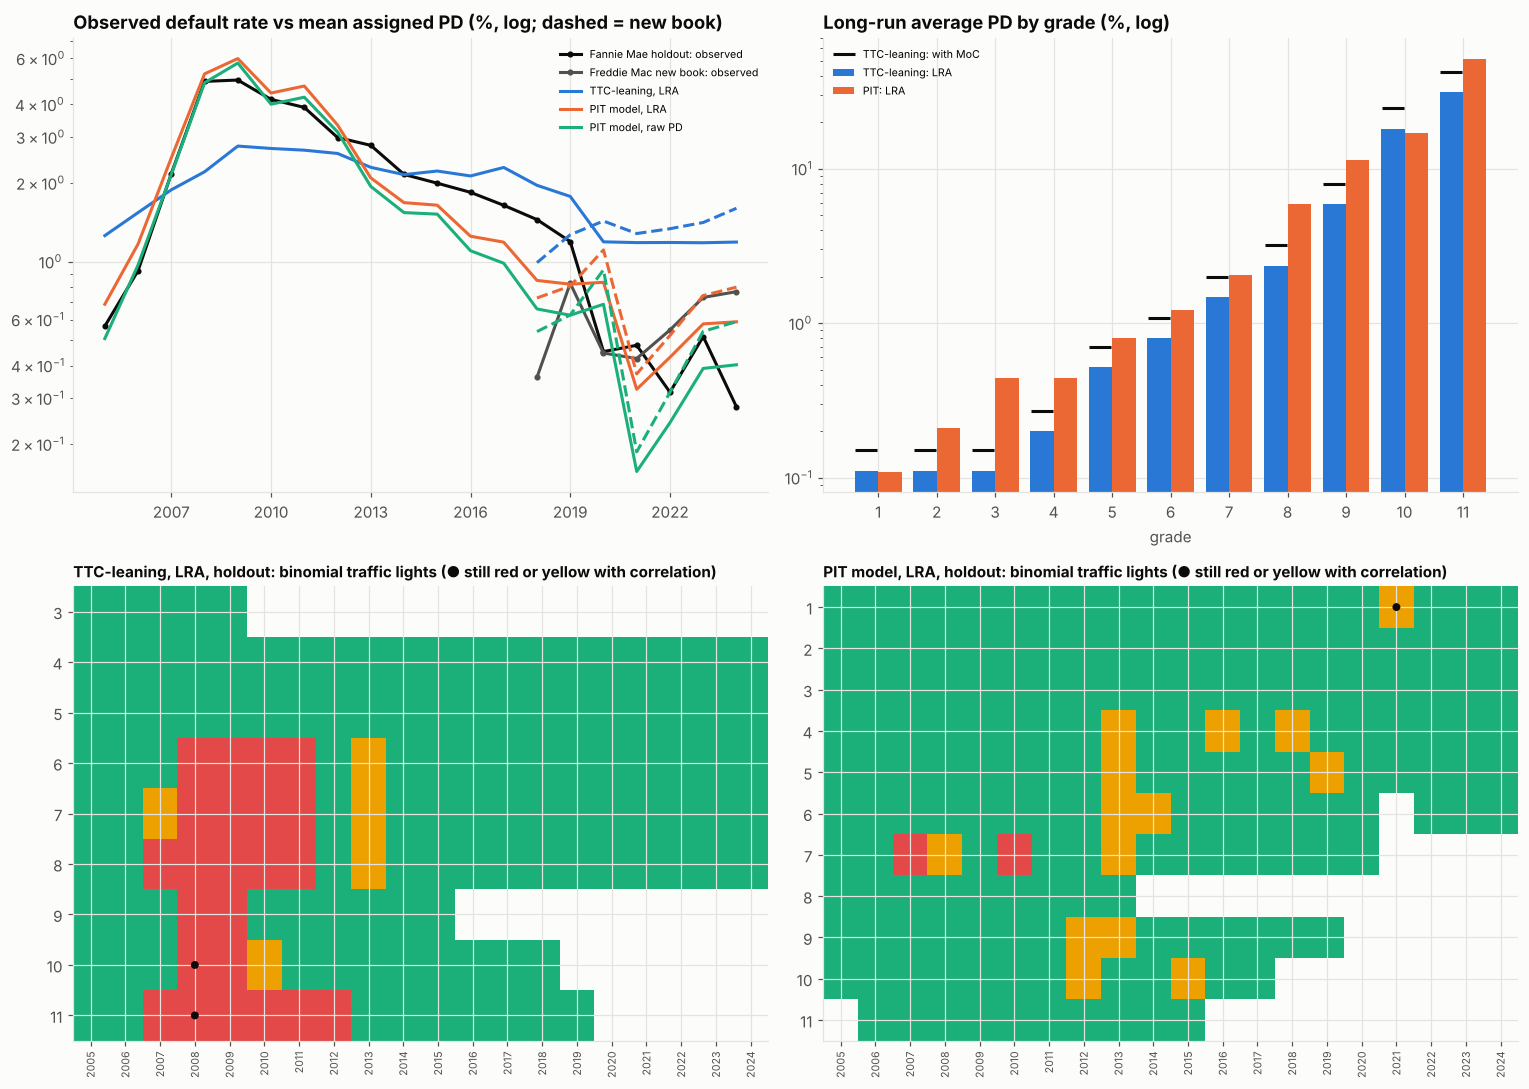

In [12]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))
a = ax[0, 0]
for (smp, lab), col in zip(
    [("holdout", "Fannie Mae holdout"), ("new book", "Freddie Mac new book")],
    [INK, INK_2],
):
    y = BY_YEAR.loc[smp].loc["TTC-leaning, LRA"]
    a.plot(
        y.index,
        y["default rate"] * 100,
        color=col,
        lw=2,
        marker="o",
        ms=3,
        label=f"{lab}: observed",
    )
for name, col in zip(
    ["TTC-leaning, LRA", "PIT model, LRA", "PIT model, raw PD"], PALETTE
):
    for smp, ls in [("holdout", "-"), ("new book", "--")]:
        y = BY_YEAR.loc[smp].loc[name]
        a.plot(
            y.index,
            y["mean PD"] * 100,
            color=col,
            ls=ls,
            label=name if smp == "holdout" else None,
        )
a.set_yscale("log")
a.set_title(
    "Observed default rate vs mean assigned PD (%, log; dashed = new book)"
)
a.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
a.legend(fontsize=7)
a = ax[0, 1]
xpos = np.arange(len(GRADES))
a.bar(
    xpos - 0.2,
    LRA["ttc"] * 100,
    0.4,
    color=PALETTE[0],
    label="TTC-leaning: LRA",
)
a.bar(xpos + 0.2, LRA["pit"] * 100, 0.4, color=PALETTE[1], label="PIT: LRA")
a.plot(
    xpos - 0.2,
    FINAL["ttc"] * 100,
    "_",
    color=INK,
    ms=14,
    mew=2,
    label="TTC-leaning: with MoC",
)
a.set_yscale("log")
a.set_xticks(xpos)
a.set_xticklabels(GRADES)
a.set_xlabel("grade")
a.set_title("Long-run average PD by grade (%, log)")
a.legend(fontsize=7)
for a, sysname in zip(ax[1], ["TTC-leaning, LRA", "PIT model, LRA"]):
    t = TESTS[(TESTS["sample"] == "holdout") & (TESTS["system"] == sysname)]
    code_map = {"green": 0, "yellow": 1, "red": 2}
    grid = (
        t.pivot(index="grade", columns="year", values="light_binomial")
        .replace(code_map)
        .astype(float)
    )
    vgrid = (
        t.pivot(index="grade", columns="year", values="light_vasicek")
        .replace(code_map)
        .astype(float)
    )
    a.imshow(
        grid,
        cmap=ListedColormap([PALETTE[2], PALETTE[3], PALETTE[7]]),
        vmin=0,
        vmax=2,
        aspect="auto",
    )
    for (i, j), v in np.ndenumerate(vgrid.to_numpy()):
        if v >= 1:
            a.text(j, i, "●", ha="center", va="center", fontsize=7, color=INK)
    a.set_xticks(range(grid.shape[1]))
    a.set_xticklabels(grid.columns, rotation=90, fontsize=7)
    a.set_yticks(range(grid.shape[0]))
    a.set_yticklabels(grid.index)
    a.set_title(
        f"{sysname}, holdout: binomial traffic lights (● still red or yellow"
        " with correlation)",
        fontsize=10,
    )
fig.tight_layout()
save_fig(fig, "01_pd_calibration")
plt.show()

In [13]:
dash = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=(
        "AUC by snapshot year",
        (
            "Share of grade-years red or yellow: independent vs correlated"
            " defaults"
        ),
        "Jeffreys p-values, holdout (below 5% = underestimation)",
        "Margin of conservatism (% of LRA)",
    ),
)
for (smp, n), col in zip(
    [(a, b) for a in ["holdout", "new book"] for b in SYSTEMS], PALETTE
):
    y = AUC.loc[smp][n].dropna()
    dash.add_trace(
        go.Scatter(x=y.index, y=y, name=f"{n}, {smp}", line_color=col), 1, 1
    )
T = TOTALS.reset_index()
lab = T["system"] + " · " + T["sample"]
dash.add_trace(
    go.Bar(x=lab, y=T["red or yellow, binomial"] * 100, name="binomial"), 1, 2
)
dash.add_trace(
    go.Bar(
        x=lab, y=T["red or yellow, Vasicek"] * 100, name="Vasicek, R = 15%"
    ),
    1,
    2,
)
for name, col in zip(["TTC-leaning, LRA", "PIT model, LRA"], PALETTE):
    t = TESTS[(TESTS["sample"] == "holdout") & (TESTS["system"] == name)]
    dash.add_trace(
        go.Scatter(
            x=t["year"] + (t["grade"] - 6) * 0.04,
            y=t["p_jeffreys"],
            mode="markers",
            name=name,
            marker=dict(size=5, color=col),
            text="grade " + t["grade"].astype(str),
        ),
        2,
        1,
    )
dash.add_trace(
    go.Bar(x=MOC.index, y=MOC.values * 100, name="MoC", marker_color=INK), 2, 2
)
dash.update_layout(
    height=950,
    width=1400,
    template="simple_white",
    barmode="group",
    title=(
        "PD calibration under validation: U.S. mortgages, Fannie Mae 2005–2024"
        " and Freddie Mac 2018–2024"
    ),
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 11. Reading the results and limitations

**Twenty years of mortgage defaults.** The notebook builds 1.45 million loan-years from 397,000 loans.
- **Fannie Mae book:** of the loans that were performing at the end of 2005, 0.6% defaulted within a year. For loans performing at the end of 2008 and 2009 the figure was 5.0% and 5.1%. It then fell to about 1.5% by 2018 and to 0.3–1.1% in 2020–2024.
- **Freddie Mac book (2018–2023 originations):** annual default rates of 0.4–0.8%.

**Forbearance.** Counting arrears during COVID-19 forbearance as defaults would have put the 2020 default rate at 4.9% for the new book and 4.6% for the old one, instead of 0.8% and 1.6%. A validation that ignored the moratorium rules would have flagged almost every grade as underestimated in 2020.

**Discrimination.** The point-in-time model ranks borrowers better than the through-the-cycle-leaning scorecard. Its average annual AUC is 0.82 against 0.79 on the held-out loans and 0.85 against 0.82 on the new book. Both lose discrimination in 2019–2020, when defaults were driven by the pandemic rather than by borrower attributes.

**The long-run average depends on the window.** The mean of the twenty annual default rates of the calibration loans is 2.19%. A bank that had only the boom years 2005–2006 would have calibrated to 0.78%; one with only the crisis years, to 4.24%; one with 2013–2019, to 1.95%. A middle grade of the scorecard (grade 7) has an LRA of 0.71%, 2.91% or 1.29% depending on the window.

The observation period is not benign. The bank delinquency rate on single-family mortgages averaged 4.9% in the outcome years 2006–2025 against 3.7% since 1991, so the representativeness test calls for no upward adjustment. Under the EBA guidelines no downward adjustment is made either.

**Margin of conservatism.** Missing debt-to-income ratios add 0.4% of the LRA and representativeness adds nothing. The general estimation error dominates: with twenty serially correlated annual rates, the 90th percentile of their block-bootstrapped mean is 35% above the LRA. The final PDs are therefore 35% above the long-run averages.

**Through-the-cycle grades fail the binomial test in a recession.** On the held-out Fannie Mae loans, the scorecard's grades carried PDs averaging 2.2–2.8% in 2008–2011, while 3.9–5.0% of the loans defaulted. Twenty of 34 grade-years in those years were red under the binomial test, and the Hosmer–Lemeshow test rejected every year.

These are not calibration failures: a TTC PD is meant to be exceeded in a bad year. With defaults correlated through one factor at Basel's mortgage correlation of 15%, none of the grade-years in the whole period is red and only 1% are yellow. In the benign years after 2019 the same grades overestimate (PD 1.2% against default rates of 0.3–0.5%).

| Held-out loans, all years | Red, binomial | Red or yellow, binomial | Red or yellow, correlated | Jeffreys: underestimated | Jeffreys: overestimated |
|---|---|---|---|---|---|
| TTC-leaning, LRA | 16% | 19% | 1% | 20% | 22% |
| TTC-leaning, final PD with MoC | 8% | 11% | 0% | 11% | 39% |
| PIT model, LRA | 1% | 9% | 1% | 12% | 24% |
| PIT model, raw PD | 3% | 15% | 3% | 19% | 9% |

**Point-in-time grades pass because the borrowers move, not the PDs.**
- **Crisis:** in 2008–2011 only one of 44 PIT grade-years was red. As house prices fell and unemployment rose, borrowers migrated to worse grades, each with its own long-run PD, so the average assigned PD tracked the default rate.
- **Migration:** 57% of loans change PIT grade each year and 16% move by two grades or more, against 30% and 4% for the scorecard.
- **Degree of point-in-time-ness** (slope of the logit of the average PD on the logit of the default rate across years): 1.0 for the PIT model's raw PDs and 0.9 for its grade LRAs, against 0.3 for the scorecard.

**The margin of conservatism trades one failure for another.** Adding the 35% margin halves the red grade-years of the scorecard in the crisis (11 of 34 instead of 20). But the share of grade-years where the Jeffreys test finds overestimation rises to 39%, and Hosmer–Lemeshow rejects in 90% of years. Validation standards focus on underestimation; a validator should still report how conservative the PDs are, because capital follows them.

**On the newer book the systems diverge.**
- **TTC-leaning, LRA:** never red or yellow on the Freddie Mac loans of 2018–2024. Its PDs (1.0–1.6% on average) are about twice the observed default rates, and the Jeffreys test finds overestimation in 76% of grade-years. The calibration reflects a crisis that post-2008 underwriting has so far not repeated.
- **PIT model, raw PD:** underestimates. In 2021–2024 rising house prices pushed mark-to-market LTVs down, and the model, trained on 2005–2012, assigned average PDs of 0.2–0.6% while 0.4–0.8% of loans defaulted. Twenty-five of 43 grade-years were red.
- **PIT model, LRA:** in between, with 17% of grade-years red under the binomial test and 3% red or yellow with correlation.

A model that maps today's benign conditions into very low PDs needs either a TTC calibration or a margin that the data from a stressed period alone does not provide.

**Monotonicity.** Observed default rates rise from the best to the worst grade in both systems and both samples, with no inversions. At most one adjacent pair per system is not significantly different, always among the best grades, where defaults are few.

**What this means for PD validation.**
- **Read the tests against the rating philosophy:** a TTC system should be expected to fail binomial tests in a recession and pass easily in a boom. A correlation-adjusted test or a test of the long-run average against the average of observed rates is the right check, and annual reds in a downturn are evidence of the cycle, not of miscalibration.
- **Hosmer–Lemeshow and binomial tests with large samples:** with tens of thousands of loans per year, almost any deviation is significant; the Jeffreys and correlated traffic-light results are more informative.
- **The window matters more than the model:** an LRA without a downturn year can be one third of the full-cycle figure. A representativeness test against a longer external series is a cheap safeguard.
- **Margins of conservatism are mostly about estimation error:** with one cycle of data, the statistical uncertainty of the long-run average alone adds a third to the PDs.

**Limitations.**
- **Data:** the Fannie Mae loans are a closed book: after 2008 it ages and is left with the loans that survived the crisis, so later years mix the cycle with seasoning. The two books come from different lenders and periods, and only samples of 50,000 loans per vintage are used.
- **Default definition:** the 90-days-past-due flag cannot see unlikeliness to pay, and the treatment of forbearance follows a simple rule (arrears during a plan do not count).
- **Models:** the scorecard is not fully through-the-cycle, because it includes delinquency status and loan age. Grade LRAs for sparse grades rely on few years and on pooling.
- **Tests:** the correlated test uses Basel's correlation, not one estimated for this portfolio, and grade-years are not independent of each other.

In [14]:
BOOKS.to_csv(OUT_DIR / "default_rates_by_book_and_year.csv")
GR.to_csv(OUT_DIR / "grade_long_run_averages.csv")
WIN.to_csv(OUT_DIR / "lra_by_observation_window.csv")
MOC.to_csv(OUT_DIR / "margin_of_conservatism.csv")
TESTS.to_csv(OUT_DIR / "grade_year_tests.csv", index=False)
BY_YEAR.to_csv(OUT_DIR / "tests_by_year.csv")
TOTALS.to_csv(OUT_DIR / "tests_summary.csv")
AUC.to_csv(OUT_DIR / "auc_by_year.csv")
MONO_T.to_csv(OUT_DIR / "monotonicity.csv")
PITNESS.to_csv(OUT_DIR / "migration_and_pitness.csv")
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_pd_calibration.png, auc_by_year.csv, dashboard.html, dashboard.png, default_rates_by_book_and_year.csv, grade_long_run_averages.csv, grade_year_tests.csv, lra_by_observation_window.csv, margin_of_conservatism.csv, migration_and_pitness.csv, monotonicity.csv, tests_by_year.csv, tests_summary.csv


## References

### Regulation and supervisory practice

- Basel Committee on Banking Supervision. (2006). *International convergence of capital measurement and capital standards: A revised framework, comprehensive version*. Bank for International Settlements. https://www.bis.org/publ/bcbs128.htm
- Basel Committee on Banking Supervision. (2005). *Studies on the validation of internal rating systems* (Working Paper No. 14). Bank for International Settlements. https://www.bis.org/publ/bcbs_wp14.htm
- Basel Committee on Banking Supervision. (2017). *Basel III: Finalising post-crisis reforms*. Bank for International Settlements. https://www.bis.org/bcbs/publ/d424.htm
- European Banking Authority. (2017). *Guidelines on PD estimation, LGD estimation and the treatment of defaulted exposures* (EBA/GL/2017/16). https://www.eba.europa.eu/regulation-and-policy/model-validation/guidelines-on-pd-lgd-estimation-and-treatment-of-defaulted-assets
- European Banking Authority. (2020). *Guidelines on legislative and non-legislative moratoria on loan repayments applied in the light of the COVID-19 crisis* (EBA/GL/2020/02). https://www.eba.europa.eu/regulation-and-policy/credit-risk/guidelines-legislative-and-non-legislative-moratoria-loan-repayments-applied-light-covid-19-crisis
- European Central Bank. (2019). *Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk*. https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf

### Credit-risk validation and statistics

- Tasche, D. (2003). *A traffic lights approach to PD validation* (arXiv:cond-mat/0305038). https://arxiv.org/abs/cond-mat/0305038
- Vasicek, O. (2002). The distribution of loan portfolio value. *Risk, 15*(12), 160–162.
- Hosmer, D. W., & Lemeshow, S. (1980). Goodness of fit tests for the multiple logistic regression model. *Communications in Statistics – Theory and Methods, 9*(10), 1043–1069. https://doi.org/10.1080/03610928008827941
- Künsch, H. R. (1989). The jackknife and the bootstrap for general stationary observations. *The Annals of Statistics, 17*(3), 1217–1241. https://doi.org/10.1214/aos/1176347265
- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*. https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html

### Data

- Fannie Mae. (2026). *Single-Family Loan Performance Data* [Data set]. https://capitalmarkets.fanniemae.com/credit-risk-transfer/single-family-credit-risk-transfer/fannie-mae-single-family-loan-performance-data
- Freddie Mac. (2026). *Single-Family Loan-Level Dataset* [Data set]. https://www.freddiemac.com/research/datasets/sf-loanlevel-dataset
- Federal Housing Finance Agency, U.S. Bureau of Labor Statistics, Freddie Mac and Board of Governors of the Federal Reserve System. (2026). *State house price indexes, state unemployment rates, 30-year fixed mortgage average and delinquency rate on single-family residential mortgages* [Data sets]. Federal Reserve Bank of St. Louis (FRED). https://fred.stlouisfed.org/